# October Task #3: Compare the modeling approaches on validation

**Goal.** Score every approach on the **validation** split with the same shared code
(`src/uplift_eval.py`), then decide which approaches are clearly better than random
and which are ties.

**Rules this notebook follows**
- Validation data only. `test.csv.gz` is never loaded here.
- Features are `f0` to `f11` only. `exposure` is never used.
- Every model is scored on **all** validation rows (treatment and control). Uplift needs both
  groups, so a model that is only scored on treated rows cannot be evaluated.
- Every model uses the same definitions: ten groups, uplift = treatment visit rate minus control
  visit rate, 95% CI = uplift +/- 1.96 x SE, incremental visits = group size x uplift.

**Score handoff.** Each teammate saves one NumPy array of validation scores, in the same row
order as `validation.csv.gz`, to `scores/val_<name>.npy`:

| File | Model |
|---|---|
| `scores/val_t_learner.npy` | T-learner (October Task #1) |
| `scores/val_transformed_outcome.npy` | Transformed-outcome model (October Task #2) |

Random ranking and the response model are built inside this notebook. Models whose file is missing
are skipped, so this notebook runs at any stage.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.uplift_eval import (
    FEATURE_COLUMNS, area_above_random, cumulative_uplift, overall_itt,
    percent_view, plot_cumulative, plot_uplift_by_group, random_ranking_null,
    summarize_null, uplift_by_group,
)

RANDOM_SEED = 2026
TOP_FRACTION = 0.30          # "top 30% of the ranked audience" is our headline cutoff
SCORE_DIR = ROOT / "scores"

train = pd.read_csv(ROOT / "data" / "train.csv.gz")
val = pd.read_csv(ROOT / "data" / "validation.csv.gz")

t_val = val["treatment"].to_numpy()
y_val = val["visit"].to_numpy()
print(f"train rows: {len(train):,}   validation rows: {len(val):,}")

train rows: 700,000   validation rows: 150,000


## 1. Reference point: overall effect on validation

Every ranking is judged against this. A useful ranking should concentrate incremental visits in its
top groups, so those groups should show uplift above this overall line.

In [2]:
itt = overall_itt(t_val, y_val)
pd.Series(itt).round(5).to_frame("validation overall ITT")

,validation overall ITT
n,150000.00000
n_treatment,127493.00000
n_control,22507.00000
visits_treatment,6170.00000
visits_control,871.00000
treatment_rate,0.04839
control_rate,0.03870
uplift,0.00970
ci_low,0.00691
ci_high,0.01248


## 2. Build the scores

- **Random ranking:** seeded random scores.
- **Response model:** logistic regression trained on **treatment rows of the training split**, then
  used to score **all** validation rows. (The standalone response notebooks only score treated
  validation rows, which can't be turned into an uplift table.)
- **T-learner and transformed-outcome:** loaded from `scores/` if the files exist.

In [3]:
def load_scores(name):
    path = SCORE_DIR / f"val_{name}.npy"
    if not path.exists():
        print(f"[skipped] {path.name} not found yet")
        return None
    arr = np.load(path)
    assert arr.shape == (len(val),), f"{path.name}: expected {len(val)} scores, got {arr.shape}"
    assert np.isfinite(arr).all(), f"{path.name}: contains NaN or infinite values"
    print(f"[loaded]  {path.name}")
    return arr


scores = {}

# 1) Random ranking
scores["Random"] = np.random.default_rng(RANDOM_SEED).random(len(val))

# 2) Response model (likely visitors, not uplift)
treated = train["treatment"] == 1
response_model = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
)
response_model.fit(train.loc[treated, FEATURE_COLUMNS], train.loc[treated, "visit"])
scores["Response model"] = response_model.predict_proba(val[FEATURE_COLUMNS])[:, 1]

# 3) and 4) uplift models from teammates
for label, name in [("T-learner", "t_learner"), ("Transformed outcome", "transformed_outcome")]:
    arr = load_scores(name)
    if arr is not None:
        scores[label] = arr

print("Models compared:", list(scores))

[loaded]  val_t_learner.npy
[loaded]  val_transformed_outcome.npy
Models compared: ['Random', 'Response model', 'T-learner', 'Transformed outcome']


## 3. Uplift by group for every model

Group 1 = highest score. Each table has treatment and control counts, visits, rates, uplift,
95% CI, and incremental visits. The dashed gray line is zero. The orange line is the overall effect.

In [4]:
tables, curves = {}, {}
for name, s in scores.items():
    tables[name] = uplift_by_group(s, t_val, y_val)
    curves[name] = cumulative_uplift(s, t_val, y_val)

for name, table in tables.items():
    print(f"\n=== {name} ===")
    display(percent_view(table))


=== Random ===


,group,n,n_treatment,n_control,visits_treatment,visits_control,treatment_rate,control_rate,uplift,ci_low,ci_high,incremental_visits,incremental_ci_low,incremental_ci_high
0,1,15000,12751,2249,611,102,4.792,4.535,0.256,-0.680,1.193,38.5,-102.0,178.9
1,2,15000,12832,2168,594,89,4.629,4.105,0.524,-0.387,1.435,78.6,-58.1,215.2
2,3,15000,12651,2349,642,84,5.075,3.576,1.499,0.656,2.341,224.8,98.4,351.2
3,4,15000,12745,2255,567,81,4.449,3.592,0.857,0.009,1.704,128.5,1.4,255.6
4,5,15000,12777,2223,641,91,5.017,4.094,0.923,0.017,1.830,138.5,2.5,274.5
5,6,15000,12749,2251,601,99,4.714,4.398,0.316,-0.607,1.240,47.4,-91.1,185.9
6,7,15000,12758,2242,614,74,4.813,3.301,1.512,0.684,2.340,226.8,102.7,350.9
7,8,15000,12669,2331,625,71,4.933,3.046,1.887,1.094,2.680,283.1,164.2,402.1
8,9,15000,12770,2230,655,94,5.129,4.215,0.914,-0.004,1.832,137.1,-0.5,274.7
9,10,15000,12791,2209,620,86,4.847,3.893,0.954,0.066,1.842,143.1,9.8,276.4



=== Response model ===


,group,n,n_treatment,n_control,visits_treatment,visits_control,treatment_rate,control_rate,uplift,ci_low,ci_high,incremental_visits,incremental_ci_low,incremental_ci_high
0,1,15000,12894,2106,4621,648,35.838,30.769,5.069,2.931,7.207,760.4,439.7,1081.1
1,2,15000,12738,2262,1012,131,7.945,5.791,2.153,1.082,3.224,323.0,162.4,483.7
2,3,15000,12790,2210,245,43,1.916,1.946,-0.030,-0.653,0.593,-4.5,-98.0,88.9
3,4,15000,12707,2293,94,13,0.740,0.567,0.173,-0.169,0.514,25.9,-25.3,77.2
4,5,15000,12758,2242,55,11,0.431,0.491,-0.060,-0.370,0.251,-8.9,-55.5,37.7
5,6,15000,12719,2281,19,7,0.149,0.307,-0.158,-0.394,0.079,-23.6,-59.1,11.9
6,7,15000,12689,2311,17,4,0.134,0.173,-0.039,-0.220,0.142,-5.9,-33.0,21.3
7,8,15000,12733,2267,21,3,0.165,0.132,0.033,-0.133,0.198,4.9,-19.9,29.7
8,9,15000,12748,2252,17,2,0.133,0.089,0.045,-0.094,0.183,6.7,-14.1,27.4
9,10,15000,12717,2283,69,9,0.543,0.394,0.148,-0.139,0.435,22.3,-20.8,65.3



=== T-learner ===


,group,n,n_treatment,n_control,visits_treatment,visits_control,treatment_rate,control_rate,uplift,ci_low,ci_high,incremental_visits,incremental_ci_low,incremental_ci_high
0,1,15000,12975,2025,3354,400,25.850,19.753,6.097,4.206,7.987,914.5,630.9,1198.1
1,2,15000,12765,2235,758,106,5.938,4.743,1.195,0.223,2.167,179.3,33.5,325.1
2,3,15000,12741,2259,316,63,2.480,2.789,-0.309,-1.039,0.422,-46.3,-155.9,63.3
3,4,15000,12679,2321,177,32,1.396,1.379,0.017,-0.499,0.534,2.6,-74.9,80.1
4,5,15000,12671,2329,97,25,0.766,1.073,-0.308,-0.753,0.137,-46.2,-113.0,20.6
5,6,15000,12726,2274,67,14,0.526,0.616,-0.089,-0.434,0.256,-13.4,-65.2,38.4
6,7,15000,12657,2343,67,11,0.529,0.469,0.060,-0.244,0.364,9.0,-36.7,54.6
7,8,15000,12780,2220,45,8,0.352,0.360,-0.008,-0.278,0.261,-1.2,-41.7,39.2
8,9,15000,12758,2242,28,5,0.219,0.223,-0.004,-0.215,0.208,-0.5,-32.3,31.2
9,10,15000,12741,2259,1261,207,9.897,9.163,0.734,-0.564,2.032,110.1,-84.6,304.8



=== Transformed outcome ===


,group,n,n_treatment,n_control,visits_treatment,visits_control,treatment_rate,control_rate,uplift,ci_low,ci_high,incremental_visits,incremental_ci_low,incremental_ci_high
0,1,15000,12998,2002,3417,417,26.289,20.829,5.459,3.526,7.393,818.9,529.0,1108.9
1,2,15000,12708,2292,1542,257,12.134,11.213,0.921,-0.490,2.332,138.2,-73.5,349.8
2,3,15000,12746,2254,559,77,4.386,3.416,0.970,0.140,1.799,145.4,20.9,269.9
3,4,15000,12710,2290,232,39,1.825,1.703,0.122,-0.457,0.701,18.3,-68.5,105.2
4,5,15000,12684,2316,101,23,0.796,0.993,-0.197,-0.629,0.236,-29.5,-94.4,35.3
5,6,15000,12783,2217,88,14,0.688,0.631,0.057,-0.303,0.416,8.5,-45.4,62.5
6,7,15000,12662,2338,81,18,0.640,0.770,-0.130,-0.511,0.250,-19.5,-76.6,37.6
7,8,15000,12765,2235,35,5,0.274,0.224,0.050,-0.165,0.266,7.6,-24.8,40.0
8,9,15000,12743,2257,9,2,0.071,0.089,-0.018,-0.149,0.113,-2.7,-22.4,17.0
9,10,15000,12694,2306,106,19,0.835,0.824,0.011,-0.390,0.413,1.7,-58.6,61.9


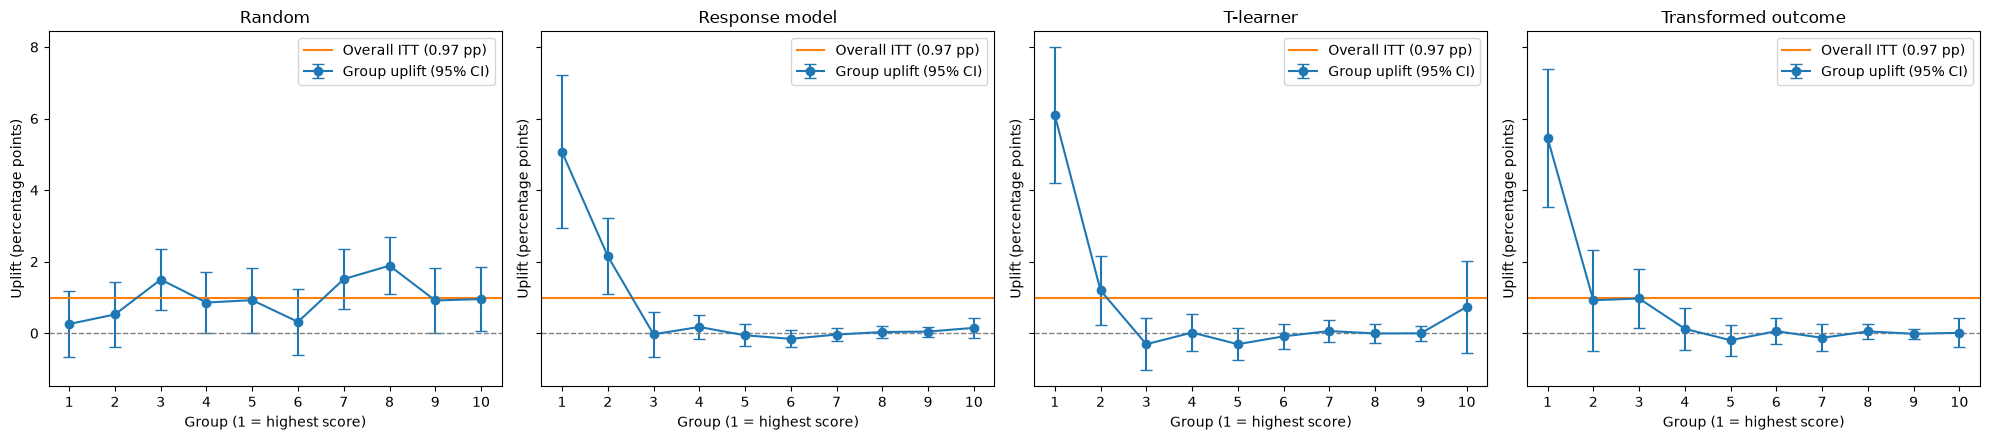

In [5]:
fig, axes = plt.subplots(1, len(scores), figsize=(5 * len(scores), 4.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, (name, table) in zip(axes, tables.items()):
    plot_uplift_by_group(table, itt=itt, title=name, ax=ax)
plt.tight_layout()
plt.show()

## 4. Cumulative incremental visits

If we target only the top share of the ranked audience, how many incremental visits do we capture?
A useful model rises above the dashed random line early. Shaded bands are 95% CIs.

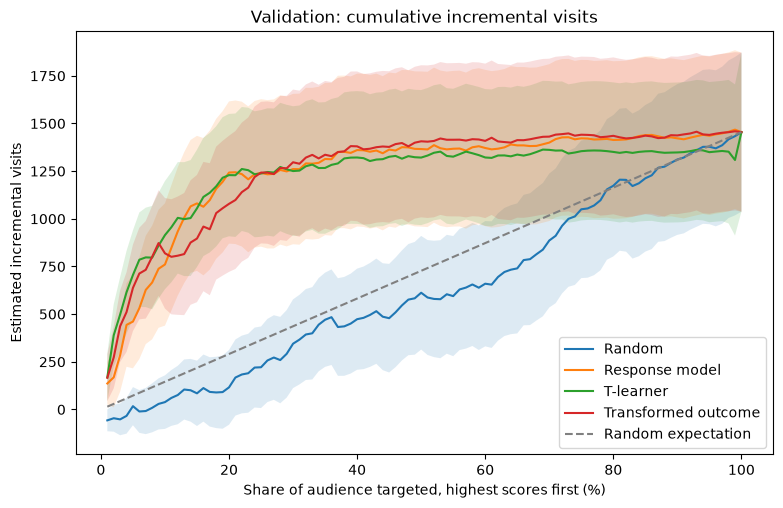

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_cumulative(curves, title="Validation: cumulative incremental visits", ax=ax)
plt.show()

## 5. One-row-per-model summary

- `top30_*` = the top 30% of the ranking, pooled into one audience.
- `area_above_random` = average gap between the curve and the random line (0 = no better than random).
- `best_minus_worst_pp` = spread between the best and worst group. This is a noisy number, so don't
  rank models on it alone.

In [7]:
rows = []
for name in scores:
    tab, cur = tables[name], curves[name]
    r = cur.iloc[(cur["fraction_targeted"] - TOP_FRACTION).abs().argmin()]
    rows.append({
        "model": name,
        "top_group_uplift_pp": tab["uplift"].iloc[0] * 100,
        "top30_uplift_pp": r["uplift"] * 100,
        "top30_incremental_visits": r["incremental_visits"],
        "top30_inc_ci_low": r["incremental_ci_low"],
        "top30_inc_ci_high": r["incremental_ci_high"],
        "area_above_random": area_above_random(cur),
        "best_minus_worst_pp": (tab["uplift"].max() - tab["uplift"].min()) * 100,
    })
summary = pd.DataFrame(rows).set_index("model")
print(f"Overall ITT on validation: {itt['uplift'] * 100:.3f} pp "
      f"-> {itt['incremental_visits']:.0f} incremental visits in {itt['n']:,} records")
summary.round(3)

Overall ITT on validation: 0.970 pp -> 1454 incremental visits in 150,000 records


,top_group_uplift_pp,top30_uplift_pp,top30_incremental_visits,top30_inc_ci_low,top30_inc_ci_high,area_above_random,best_minus_worst_pp
model,,,,,,,
Random,0.256,0.766,344.853,112.074,577.631,-0.069,1.631
Response model,5.069,2.802,1261.047,866.648,1655.447,0.355,5.227
T-learner,6.097,2.779,1250.390,910.315,1590.465,0.343,6.405
Transformed outcome,5.459,2.881,1296.544,915.105,1677.983,0.362,5.656


## 6. Is any model outside what a random ranking produces by chance?

We score the same validation data with 200 different random rankings. A real model should beat the
spread of these, not just zero. (This captures randomness in the *ranking* only, not sampling noise in
the validation data itself, so treat it as a minimum bar.)

In [8]:
null_df = random_ranking_null(t_val, y_val, n_seeds=200, top_fraction=TOP_FRACTION)
null_summary = summarize_null(null_df)
display(null_summary.round(4))

inc_col = f"incremental_top_{int(TOP_FRACTION * 100)}pct"
check = pd.DataFrame({
    "top30_incremental_visits": summary["top30_incremental_visits"],
    "null_p97.5": null_summary.loc[inc_col, "p97.5"],
    "above_random_range?": summary["top30_incremental_visits"] > null_summary.loc[inc_col, "p97.5"],
    "area_above_random": summary["area_above_random"],
    "area_null_p97.5": null_summary.loc["area_above_random", "p97.5"],
    "area_above_random_range?": summary["area_above_random"] > null_summary.loc["area_above_random", "p97.5"],
})
check.round(3)

,median,p2.5,p97.5
top_group_uplift,0.0096,0.0011,0.0186
best_minus_worst_group,0.0134,0.0081,0.0209
incremental_top_30pct,440.8135,282.2111,630.0514
area_above_random,0.0030,-0.0708,0.0817


,top30_incremental_visits,null_p97.5,above_random_range?,area_above_random,area_null_p97.5,area_above_random_range?
model,,,,,,
Random,344.853,630.051,False,-0.069,0.082,False
Response model,1261.047,630.051,True,0.355,0.082,True
T-learner,1250.390,630.051,True,0.343,0.082,True
Transformed outcome,1296.544,630.051,True,0.362,0.082,True


## 7. Which differences are real, and which are ties?

The brief says to treat close results as ties when the uncertainty intervals substantially overlap.
Here we compare each pair on **top-30% incremental visits**. "Overlap" means the 95% CIs share any
values. Both models are scored on the same records, so this is a conservative check.

In [9]:
names = list(summary.index)
pair_rows = []
for i, a in enumerate(names):
    for b in names[i + 1:]:
        lo = max(summary.loc[a, "top30_inc_ci_low"], summary.loc[b, "top30_inc_ci_low"])
        hi = min(summary.loc[a, "top30_inc_ci_high"], summary.loc[b, "top30_inc_ci_high"])
        overlap = hi - lo
        narrower = min(
            summary.loc[a, "top30_inc_ci_high"] - summary.loc[a, "top30_inc_ci_low"],
            summary.loc[b, "top30_inc_ci_high"] - summary.loc[b, "top30_inc_ci_low"],
        )
        pair_rows.append({
            "model A": a, "model B": b,
            "difference (A - B)": summary.loc[a, "top30_incremental_visits"] - summary.loc[b, "top30_incremental_visits"],
            "CIs overlap?": overlap > 0,
            "overlap as share of narrower CI": max(overlap, 0) / narrower,
            "call": "TIE" if overlap > 0 and overlap / narrower > 0.5 else "possible difference",
        })
pairs = pd.DataFrame(pair_rows)
pairs.round(3)

,model A,model B,difference (A - B),CIs overlap?,overlap as share of narrower CI,call
0,Random,Response model,-916.195,False,0.000,possible difference
1,Random,T-learner,-905.538,False,0.000,possible difference
2,Random,Transformed outcome,-951.691,False,0.000,possible difference
3,Response model,T-learner,10.657,True,1.000,TIE
4,Response model,Transformed outcome,-35.496,True,0.970,TIE
5,T-learner,Transformed outcome,-46.153,True,0.993,TIE
